In [1]:
import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

df.head()

df['Class'].value_counts(normalize=True)


Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

In [2]:
import numpy as np


df['Amount_log'] = np.log1p(df['Amount'])

X = df.drop(columns=['Class'])

y = df['Class']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

from sklearn.preprocessing import StandardScaler



In [3]:
print(X_train.shape, X_test.shape)

(227845, 31) (56962, 31)


In [4]:
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(max_iter=1000, random_state=42)

modelo_lr.fit(X_train, y_train)

previsoes_lr = modelo_lr.predict(X_test)


c:\Users\pccsw\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [5]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

modelo_lr = LogisticRegression(max_iter=5000, random_state=42)

modelo_lr.fit(X_train_scaled, y_train)

previsoes_lr = modelo_lr.predict(X_test_scaled)



In [6]:
from sklearn.metrics import classification_report

print(classification_report(y_test, previsoes_lr))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.65      0.73        98

    accuracy                           1.00     56962
   macro avg       0.92      0.83      0.87     56962
weighted avg       1.00      1.00      1.00     56962



In [7]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)

modelo_rf.fit(X_train_scaled, y_train)

previsoes_rf = modelo_rf.predict(X_test_scaled)


In [8]:
from sklearn.metrics import classification_report

print(classification_report(y_test, previsoes_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

modelo_xgb = XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')

modelo_xgb.fit(X_train_scaled, y_train)

previsoes_xgb = modelo_xgb.predict(X_test_scaled)

print(classification_report(y_test, previsoes_xgb))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.83      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



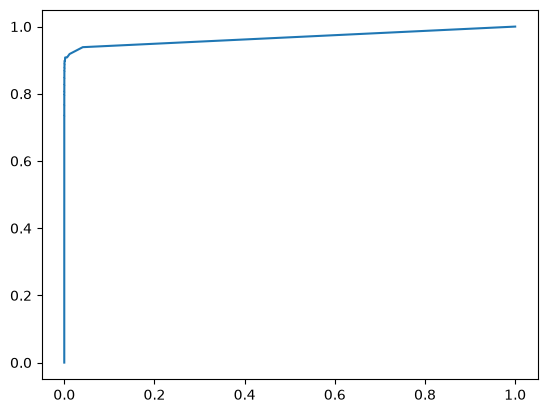

In [10]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

prob_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test, prob_rf)

auc_rf = roc_auc_score(y_test, prob_rf)

precision, recall, _ = precision_recall_curve(y_test, prob_rf)

average_precision_score(y_test, prob_rf)

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc_rf:.2f})')

plt.show()


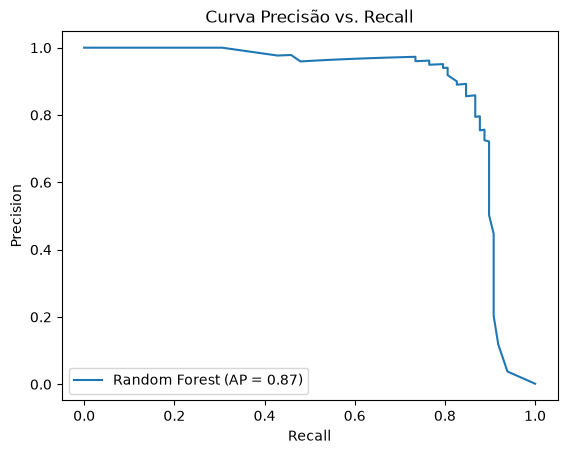

In [11]:
plt.plot(recall, precision, label=f'Random Forest (AP = {average_precision_score(y_test, prob_rf):.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precisão vs. Recall')
plt.legend()
plt.show()



In [12]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([('scaler', StandardScaler()), ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])

pipe.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['Time','V1','V2',...,'V28','Amount','Amount_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {'modelo__C': [0.01, 0.1, 1.0]}

grid = GridSearchCV(pipe, param_grid, scoring='recall', cv=3)

grid.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting,

In [14]:
print("Melhores parâmetros:", grid.best_params_)

print("Melhor recall na validação:", grid.best_score_)

previsoes_grid = grid.best_estimator_.predict(X_test)

print(classification_report(y_test, previsoes_grid))

Melhores parâmetros: {'modelo__C': 1.0}
Melhor recall na validação: 0.9162618551931528
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [15]:
probs_grid = grid.best_estimator_.predict_proba(X_test)[:, 1]

for limiar in [0.5, 0.3]:
    previsoes = (probs_grid >= limiar).astype(int)

    print(f"\nLimiar: {limiar}")
    print(classification_report(y_test, previsoes))


Limiar: 0.5
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962


Limiar: 0.3
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     56864
           1       0.03      0.92      0.05        98

    accuracy                           0.94     56962
   macro avg       0.51      0.93      0.51     56962
weighted avg       1.00      0.94      0.97     56962



In [16]:
from sklearn.model_selection import cross_val_predict

probs_validacao = cross_val_predict(
    grid.best_estimator_,
    X_train,
    y_train,
    cv=3,
    method='predict_proba'
)[:, 1]

In [17]:
for limiar in [0.5, 0.3]:
    previsoes_validacao = (probs_validacao >= limiar).astype(int)

    print(f"\nLimiar: {limiar}")
    print(classification_report(y_train, previsoes_validacao))


Limiar: 0.5
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    227451
           1       0.06      0.92      0.11       394

    accuracy                           0.98    227845
   macro avg       0.53      0.95      0.55    227845
weighted avg       1.00      0.98      0.99    227845


Limiar: 0.3
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    227451
           1       0.03      0.94      0.06       394

    accuracy                           0.95    227845
   macro avg       0.51      0.94      0.51    227845
weighted avg       1.00      0.95      0.97    227845



In [18]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X_train.columns)

importancias.sort_values(ascending=False).head(5)


V14    0.191699
V10    0.142695
V4     0.098708
V12    0.092027
V11    0.071842
dtype: float64

In [19]:
import shap

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

amostra_normal = X_test_scaled_df.loc[y_test == 0].sample(50, random_state=42)

amostra_fraude = X_test_scaled_df.loc[y_test == 1].sample(50, random_state=42)

amostra = pd.concat([amostra_normal, amostra_fraude])

explainer = shap.TreeExplainer(modelo_rf)

shap_values = explainer.shap_values(amostra)

print(type(shap_values), np.shape(shap_values))

c:\Users\pccsw\AppData\Local\Programs\Python\Python315\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<class 'numpy.ndarray'> (100, 31, 2)


In [20]:
print(type(X_test_scaled))
print(X_test_scaled.shape)
print(X_test.shape)

<class 'numpy.ndarray'>
(56962, 31)
(56962, 31)


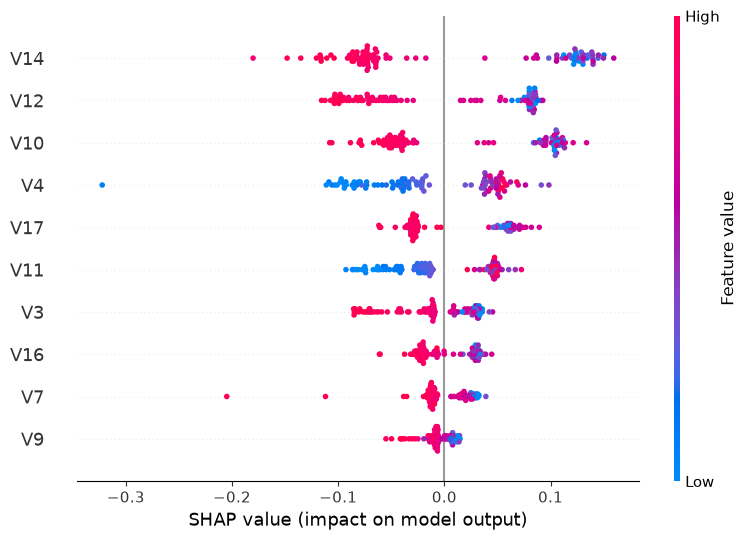

In [21]:
shap.summary_plot(
    shap_values[:, :, 1],
    amostra,
    max_display=10
)

In [22]:
y_test.loc[amostra.index].value_counts()

Class
0    50
1    50
Name: count, dtype: int64

In [23]:
fraudes_detectadas = X_test_scaled_df.loc[
    (y_test == 1) & (previsoes_rf == 1)
]

print(fraudes_detectadas.shape)

(79, 31)


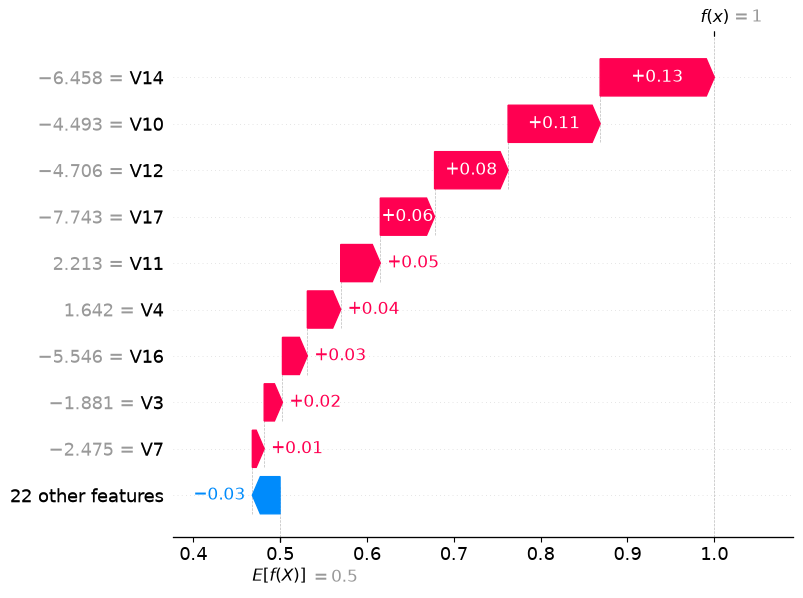

In [24]:
transacao = fraudes_detectadas.iloc[[0]]

shap_individual = explainer.shap_values(transacao)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_individual[0, :, 1],
        base_values=explainer.expected_value[1],
        data=transacao.iloc[0].values,
        feature_names=transacao.columns.tolist()
    ),
    max_display=10
)

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

resultados = []

for nome, previsoes in [
    ('Regressão Logística', previsoes_lr),
    ('Random Forest', previsoes_rf),
    ('XGBoost', previsoes_xgb),
    ('Regressão Logística Otimizada', previsoes_grid)
]:
    resultados.append({
        'Modelo': nome,
        'Precision': precision_score(y_test, previsoes),
        'Recall': recall_score(y_test, previsoes),
        'F1-score': f1_score(y_test, previsoes)
    })

df_resultados = pd.DataFrame(resultados)
df_resultados.round(4)

,Modelo,Precision,Recall,F1-score
0,Regressão Logística,0.8312,0.6531,0.7314
1,Random Forest,0.9186,0.8061,0.8587
2,XGBoost,0.8710,0.8265,0.8482
3,Regressão Logística Otimizada,0.0612,0.9184,0.1147


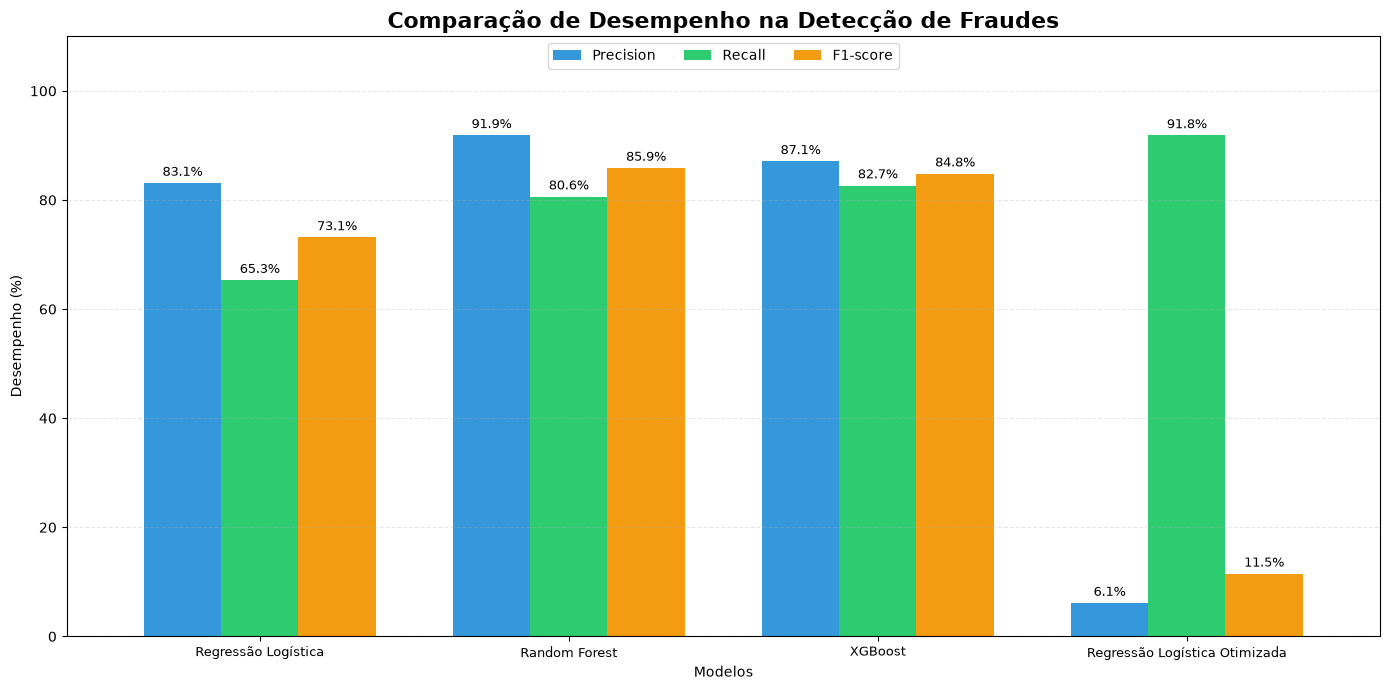

In [26]:
# Comparação visual do desempenho dos modelos
ax = df_resultados.set_index('Modelo').mul(100).plot(
    kind='bar',
    figsize=(14, 7),
    color=['#3498db', '#2ecc71', '#f39c12'],
    width=0.75
)

plt.title('Comparação de Desempenho na Detecção de Fraudes',
        fontsize=16, fontweight='bold')

plt.ylabel('Desempenho (%)')
plt.xlabel('Modelos')
plt.ylim(0, 110)
plt.xticks(rotation=0, fontsize=9)
plt.legend(loc='upper center', ncol=3)
plt.grid(axis='y', linestyle='--', alpha=0.3)

# Exibir os valores acima das barras
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=9)

plt.tight_layout()

plt.savefig(
    'comparacao_modelos.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
